# Iris - klasyfikacja gatunków irysów

## 0. Importy

In [8]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

%matplotlib inline

## 1. Wczytywanie danych

In [9]:
iris = load_iris(as_frame=True)
X = iris.data
y = iris.target

print(X.shape)
print(X.head())
print(y.value_counts().sort_index())

(150, 4)
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2
target
0    50
1    50
2    50
Name: count, dtype: int64


## 2. Podział na zbiór treningowy i walidacyjny

In [10]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(len(X_train), len(X_valid))

120 30


In [11]:
def class_counts(labels: pd.Series) -> pd.Series:
    return pd.Categorical.from_codes(labels, iris.target_names).value_counts()


split_summary = pd.DataFrame(
    {
        "cały zbiór": class_counts(y),
        "treningowy": class_counts(y_train),
        "walidacyjny": class_counts(y_valid),
    }
)
split_summary

,cały zbiór,treningowy,walidacyjny
setosa,50,40,10
versicolor,50,40,10
virginica,50,40,10


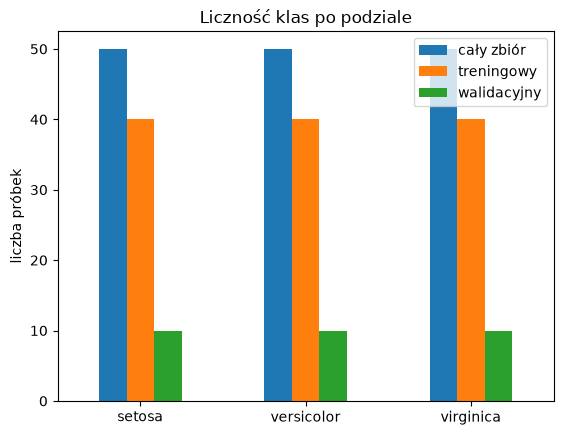

In [12]:
split_summary.plot.bar(rot=0, title="Liczność klas po podziale", ylabel="liczba próbek");

In [13]:
assert X_train.index.intersection(X_valid.index).empty
assert len(X_train) + len(X_valid) == len(X)
print("OK: zbiory są rozłączne i razem dają cały zbiór")

OK: zbiory są rozłączne i razem dają cały zbiór


## 3. Uczenie i ocena modelu

In [14]:
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_valid)

train_acc = accuracy_score(y_train, model.predict(X_train))
valid_acc = accuracy_score(y_valid, y_pred)

print(f"Trening:   {train_acc:.3f}")
print(f"Walidacja: {valid_acc:.3f}")

Trening:   0.983
Walidacja: 0.967
